# CART Regression: B.Tech Student Academic Performance Prediction
### Student Details
# CART Regression: B.Tech Student Academic Performance Prediction

### Student Details

| Particulars | Details |
|---|---|
| **Name** | KUNAPULI BALA SRI SARVANI |
| **Student ID** | 2300030957 |

**Problem Type:** Regression  
**Dataset:** Synthetic B.Tech Student Academic Performance Dataset  
**Number of Records:** 1,500  
**Target Variable:** `Final_Semester_Score` (0–100)

---

## 1. Problem statement

This notebook builds a CART regression tree to estimate a B.Tech student's final semester score using attendance, study habits, internal assessment, previous GPA, coding practice and project performance.

The dataset is synthetically generated for learning and experimentation. It does **not** contain real student records and must not be used to make real academic decisions.

## 2. What makes this a CART regression problem?

CART creates binary (two-way) splits. For regression, it selects splits that reduce squared error / variance. A terminal leaf predicts the **mean target value** of the training observations in that leaf.

This differs from the Tennis classification exercise:
- Classification CART: Gini impurity or entropy can measure class impurity.
- Regression CART: squared-error reduction (variance reduction) is used; Gini is not applicable.

## 3. Notebook workflow

1. Import libraries and set reproducibility.
2. Generate and inspect the student dataset.
3. Separate features and target; split training and testing data.
4. Calculate parent MSE and manually search for the best root split.
5. Train and visualize a full CART regression tree.
6. Apply pre-pruning using cross-validation.
7. Apply post-pruning using cost-complexity pruning.
8. Compare against a mean baseline and inspect predictions.
9. Interpret feature importance and predict for a hypothetical student.
10. Summarize observations and limitations.


## 1. Import required libraries

We use pandas and NumPy for data handling, Matplotlib and Seaborn for visualizations, and scikit-learn for CART, pruning, cross-validation and evaluation.

Decision trees do not require feature scaling, so no standardization is needed for this dataset.

In [1]:
# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Create the B.Tech student dataset

We generate 1,500 synthetic student records. The target score is influenced by multiple academic and study-related factors, with random noise so that the relationship is not perfectly predictable.

The data-generation formula is included transparently for reproducibility. The generated score is clipped to the valid 0–100 range.

In [2]:
# Step 2: Generate a synthetic B.Tech student dataset

rng = np.random.default_rng(RANDOM_STATE)
n = 1500

df = pd.DataFrame({
    "Attendance_Percentage": rng.uniform(55, 100, n).round(1),
    "Study_Hours_Per_Week": rng.uniform(1, 35, n).round(1),
    "Assignment_Average": rng.uniform(35, 100, n).round(1),
    "Internal_Marks": rng.uniform(15, 50, n).round(1),
    "Previous_Sem_GPA": rng.uniform(4.5, 10.0, n).round(2),
    "Sleep_Hours": rng.uniform(4.0, 9.5, n).round(1),
    "Coding_Hours_Per_Week": rng.uniform(0, 25, n).round(1),
    "Project_Score": rng.uniform(30, 100, n).round(1)
})

# Construct a continuous final semester score with realistic variation.
# These weights are illustrative assumptions for a synthetic teaching dataset.
sleep_effect = 100 - 5 * np.abs(df["Sleep_Hours"] - 7.5)

score = (
    0.16 * df["Attendance_Percentage"]
    + 0.15 * (df["Study_Hours_Per_Week"] / 35 * 100)
    + 0.17 * df["Assignment_Average"]
    + 0.18 * (df["Internal_Marks"] / 50 * 100)
    + 0.12 * (df["Previous_Sem_GPA"] / 10 * 100)
    + 0.06 * sleep_effect
    + 0.08 * (df["Coding_Hours_Per_Week"] / 25 * 100)
    + 0.08 * df["Project_Score"]
    + 4 * (df["Attendance_Percentage"] >= 85)
    + 3 * (df["Study_Hours_Per_Week"] >= 20)
    + rng.normal(0, 5, n)
)

df["Final_Semester_Score"] = np.clip(score, 0, 100).round(2)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head(10))

Dataset created successfully!
Dataset shape: (1500, 9)


,Attendance_Percentage,Study_Hours_Per_Week,Assignment_Average,Internal_Marks,Previous_Sem_GPA,Sleep_Hours,Coding_Hours_Per_Week,Project_Score,Final_Semester_Score
0,89.8,23.8,88.9,15.7,7.01,6.8,21.8,55.6,79.35
1,74.7,33.7,73.6,30.9,5.15,8.0,6.2,33.7,63.68
2,93.6,13.6,50.9,36.6,7.63,5.0,12.2,42.0,66.28
3,86.4,15.5,83.5,31.1,5.36,6.4,0.7,73.2,64.85
4,59.2,28.6,40.5,19.6,4.84,6.9,0.2,84.3,52.18
5,98.9,18.2,85.3,28.9,7.24,8.0,17.6,82.9,79.51
6,89.3,26.0,73.3,29.4,8.10,9.3,3.0,70.9,64.45
7,90.4,16.6,42.2,21.6,9.20,8.7,13.7,35.9,62.89
8,60.8,8.3,40.2,41.5,8.81,7.4,17.4,31.2,59.21
9,75.3,26.3,83.8,26.2,9.21,7.2,0.8,84.7,67.20


## 3. Understand the dataset

Before training, inspect the columns, data types, ranges, summary statistics and missing values. This helps verify that the target is continuous and that the dataset is ready for a regression task.

In [3]:
# Step 3: Dataset information and quality checks

print("Dataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe().round(2))

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nTarget variable summary:")
print(df["Final_Semester_Score"].describe().round(2))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Attendance_Percentage  1500 non-null   float64
 1   Study_Hours_Per_Week   1500 non-null   float64
 2   Assignment_Average     1500 non-null   float64
 3   Internal_Marks         1500 non-null   float64
 4   Previous_Sem_GPA       1500 non-null   float64
 5   Sleep_Hours            1500 non-null   float64
 6   Coding_Hours_Per_Week  1500 non-null   float64
 7   Project_Score          1500 non-null   float64
 8   Final_Semester_Score   1500 non-null   float64
dtypes: float64(9)
memory usage: 105.6 KB

Summary statistics:


,Attendance_Percentage,Study_Hours_Per_Week,Assignment_Average,Internal_Marks,Previous_Sem_GPA,Sleep_Hours,Coding_Hours_Per_Week,Project_Score,Final_Semester_Score
count,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00,1500.00
mean,77.48,17.98,67.11,32.01,7.23,6.79,12.42,65.22,68.95
std,13.12,9.82,18.80,9.93,1.58,1.59,7.27,19.97,10.23
min,55.00,1.00,35.00,15.00,4.50,4.00,0.00,30.10,37.04
25%,65.80,9.40,50.90,23.48,5.87,5.40,6.00,47.50,62.08
50%,77.20,17.90,67.30,31.60,7.22,6.80,12.70,65.50,68.78
75%,89.12,26.60,83.50,40.40,8.54,8.10,18.40,82.80,75.87
max,100.00,35.00,100.00,50.00,10.00,9.50,25.00,99.90,98.71



Missing values in each column:
Attendance_Percentage    0
Study_Hours_Per_Week     0
Assignment_Average       0
Internal_Marks           0
Previous_Sem_GPA         0
Sleep_Hours              0
Coding_Hours_Per_Week    0
Project_Score            0
Final_Semester_Score     0
dtype: int64

Number of duplicate rows: 0

Target variable summary:
count    1500.00
mean       68.95
std        10.23
min        37.04
25%        62.08
50%        68.78
75%        75.87
max        98.71
Name: Final_Semester_Score, dtype: float64


### Data Preprocessing and Encoding

All independent variables in this dataset are numerical.
Therefore, categorical encoding techniques such as Label Encoding
and One-Hot Encoding are not required.

The target variable, `Final_Semester_Score`, is also numerical,
making the dataset suitable for CART Regression.

## 4. Explore the target and feature relationships

The target distribution shows the range and spread of generated final scores. The correlation heatmap gives an initial view of linear relationships; correlation does not prove causation and does not by itself determine CART splits.

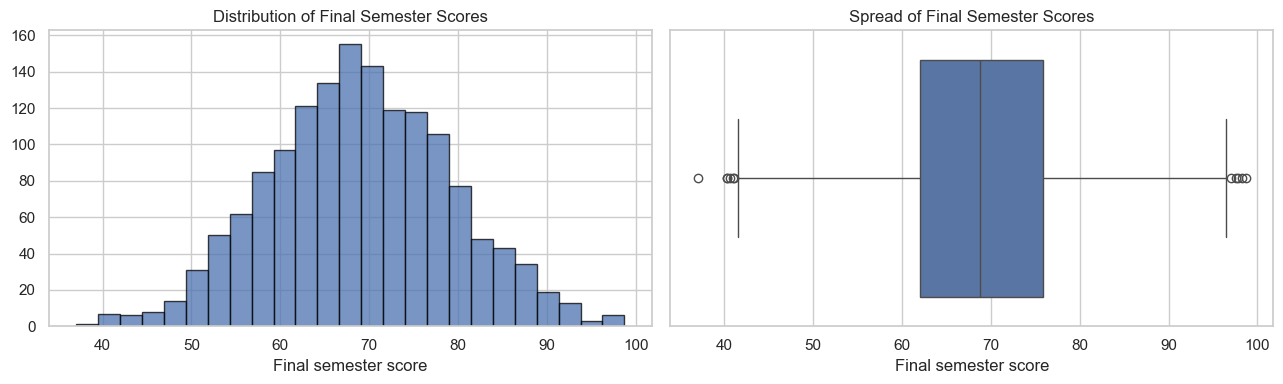

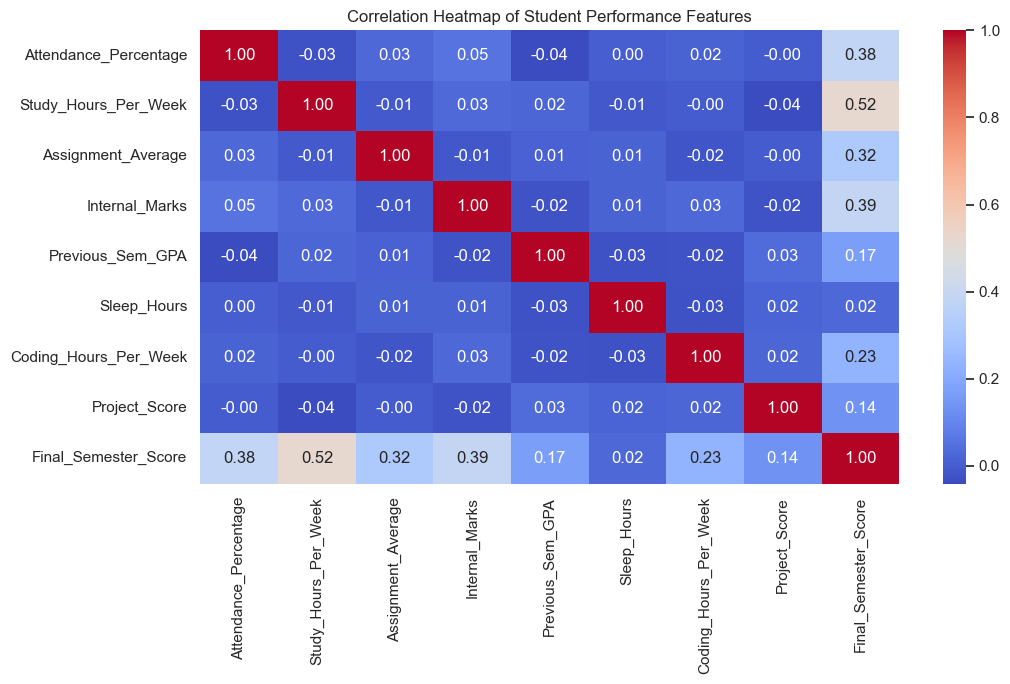

In [4]:
# Step 4: Exploratory data analysis

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(
    df["Final_Semester_Score"],
    bins=25,
    edgecolor="black",
    alpha=0.75
)
axes[0].set_title("Distribution of Final Semester Scores")
axes[0].set_xlabel("Final semester score")

sns.boxplot(
    x=df["Final_Semester_Score"],
    ax=axes[1]
)
axes[1].set_title("Spread of Final Semester Scores")
axes[1].set_xlabel("Final semester score")

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Student Performance Features")
plt.tight_layout()
plt.show()

## 5. Separate input features and target variable

`X` contains the eight input features. `y` contains the continuous final semester score that the regression tree must predict.

We reserve 25% of the records as a held-out test set. The test set is not used to select pruning parameters.

In [5]:
# Step 5: Separate features and target

X = df.drop(columns="Final_Semester_Score")
y = df["Final_Semester_Score"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable: Final_Semester_Score")
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Input features:
['Attendance_Percentage', 'Study_Hours_Per_Week', 'Assignment_Average', 'Internal_Marks', 'Previous_Sem_GPA', 'Sleep_Hours', 'Coding_Hours_Per_Week', 'Project_Score']

Target variable: Final_Semester_Score
Feature matrix shape: (1500, 8)
Target shape: (1500,)


## 6. Split the dataset into training and testing sets

- 75% of the records are used for training.
- 25% are held back for final testing.
- `random_state=42` makes the split reproducible.

The CART model learns from the training data and is evaluated on unseen test records.

In [6]:
# Step 6: Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE
)

print("Original dataset:", df.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Original dataset: (1500, 9)
Training features: (1125, 8)
Testing features: (375, 8)
Training target: (1125,)
Testing target: (375,)


## 7. Understand the regression split criterion manually

This section connects the Tennis CART exercise to CART regression.

For regression, the parent-node impurity is the mean squared error around the parent mean:

### How CART Regression Selects the Best Split

CART Regression uses Mean Squared Error (MSE) to find the best split.

**1. Parent MSE:** Measures how much the target values differ from their average.

\[
Parent\ MSE = \frac{\text{Sum of Squared Errors}}{\text{Total Records}}
\]

**2. Weighted MSE:** Calculates the combined error of the left and right child nodes.

\[
Weighted\ MSE =
\frac{N_L \times MSE_L + N_R \times MSE_R}{N}
\]

**3. MSE Reduction:** Measures how much the error decreases after splitting.

\[
MSE\ Reduction = Parent\ MSE - Weighted\ MSE
\]

**Best Split:** CART selects the split with the lowest Weighted MSE (or highest MSE Reduction).Gini impurity is a classification criterion and is not used here.

In [7]:
# Step 7: Calculate parent-node MSE

parent_mean = y_train.mean()
parent_mse = mean_squared_error(y_train, np.full(len(y_train), parent_mean))

print("Training records:", len(y_train))
print("Parent target mean:", round(parent_mean, 3))
print("Parent MSE:", round(parent_mse, 3))

Training records: 1125
Parent target mean: 69.243
Parent MSE: 103.288


## 8. Find the best root split manually for every feature

For each numeric feature, we sort its values and evaluate valid thresholds between distinct adjacent values. We calculate the weighted child MSE and MSE reduction.

This is a manual one-level CART regression split demonstration. Scikit-learn's tree implementation uses an optimized splitting procedure, so tiny floating-point or tie-breaking differences can occur.

In [8]:
# Step 8: Manual best binary split for regression

def best_regression_split(feature_values, target_values):
    x = np.asarray(feature_values, dtype=float)
    y_values = np.asarray(target_values, dtype=float)

    order = np.argsort(x)
    x_sorted = x[order]
    y_sorted = y_values[order]

    n_rows = len(y_sorted)

    # Prefix sums allow efficient SSE calculation.
    cumulative_sum = np.cumsum(y_sorted)
    cumulative_sq_sum = np.cumsum(y_sorted ** 2)

    # Candidate cuts only between distinct adjacent feature values.
    valid_positions = np.where(x_sorted[:-1] < x_sorted[1:])[0]

    left_n = valid_positions + 1
    right_n = n_rows - left_n

    left_sum = cumulative_sum[valid_positions]
    right_sum = cumulative_sum[-1] - left_sum

    left_sq = cumulative_sq_sum[valid_positions]
    right_sq = cumulative_sq_sum[-1] - left_sq

    left_sse = left_sq - (left_sum ** 2 / left_n)
    right_sse = right_sq - (right_sum ** 2 / right_n)

    weighted_mse = (left_sse + right_sse) / n_rows

    best_index = np.argmin(weighted_mse)
    position = valid_positions[best_index]

    threshold = (x_sorted[position] + x_sorted[position + 1]) / 2
    best_weighted_mse = weighted_mse[best_index]
    reduction = parent_mse - best_weighted_mse

    return threshold, best_weighted_mse, reduction


split_results = []

for feature in X_train.columns:
    threshold, weighted_mse, reduction = best_regression_split(
        X_train[feature],
        y_train
    )

    split_results.append({
        "Feature": feature,
        "Best Threshold": threshold,
        "Weighted MSE": weighted_mse,
        "MSE Reduction": reduction
    })

manual_splits = pd.DataFrame(split_results).sort_values(
    "Weighted MSE"
).reset_index(drop=True)

display(manual_splits.round(4))

print("Best feature for the first split:", manual_splits.iloc[0]["Feature"])
print("Best threshold:", round(manual_splits.iloc[0]["Best Threshold"], 3))

,Feature,Best Threshold,Weighted MSE,MSE Reduction
0,Study_Hours_Per_Week,19.850,79.7391,23.5490
1,Attendance_Percentage,86.100,89.6951,13.5930
2,Internal_Marks,27.350,90.9558,12.3323
3,Assignment_Average,65.150,95.1823,8.1058
4,Coding_Hours_Per_Week,15.250,99.0941,4.1940
5,Previous_Sem_GPA,6.855,100.2447,3.0434
6,Project_Score,72.700,101.0490,2.2391
7,Sleep_Hours,9.450,102.3291,0.9590


Best feature for the first split: Study_Hours_Per_Week
Best threshold: 19.85


## 9. Verify the manual split using a depth-1 CART regressor

A depth-1 DecisionTreeRegressor is a decision stump: it makes one binary split. We compare its selected feature and threshold with the manual calculation above.

In [9]:
# Step 9: Compare manual split with scikit-learn CART

stump = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=1,
    random_state=RANDOM_STATE
)

stump.fit(X_train, y_train)

root_feature_index = stump.tree_.feature[0]
sklearn_root_feature = X_train.columns[root_feature_index]
sklearn_threshold = stump.tree_.threshold[0]

print("Manual best feature:", manual_splits.iloc[0]["Feature"])
print("Manual threshold:", round(manual_splits.iloc[0]["Best Threshold"], 4))

print("\nScikit-learn root feature:", sklearn_root_feature)
print("Scikit-learn threshold:", round(sklearn_threshold, 4))

Manual best feature: Study_Hours_Per_Week
Manual threshold: 19.85

Scikit-learn root feature: Study_Hours_Per_Week
Scikit-learn threshold: 19.85


## 10. Train the full CART regression tree

A full tree is allowed to grow without an explicit depth or leaf-size restriction. It can fit the training records very closely, but may generalize poorly.

For regression, each leaf predicts the mean target value of the training samples that reach that leaf.

In [10]:
# Step 10: Train the full CART regression tree

full_tree = DecisionTreeRegressor(
    criterion="squared_error",
    random_state=RANDOM_STATE
)

full_tree.fit(X_train, y_train)

print("Full CART Regression Tree")
print("Tree depth:", full_tree.get_depth())
print("Number of leaves:", full_tree.get_n_leaves())
print("Training R2:", round(full_tree.score(X_train, y_train), 3))
print("Testing R2:", round(full_tree.score(X_test, y_test), 3))

Full CART Regression Tree
Tree depth: 18
Number of leaves: 1124
Training R2: 1.0
Testing R2: 0.446


## 11. Visualize the full CART tree

A large tree can be difficult to read. The visualization below displays only the first few levels while retaining the full model for prediction and evaluation.

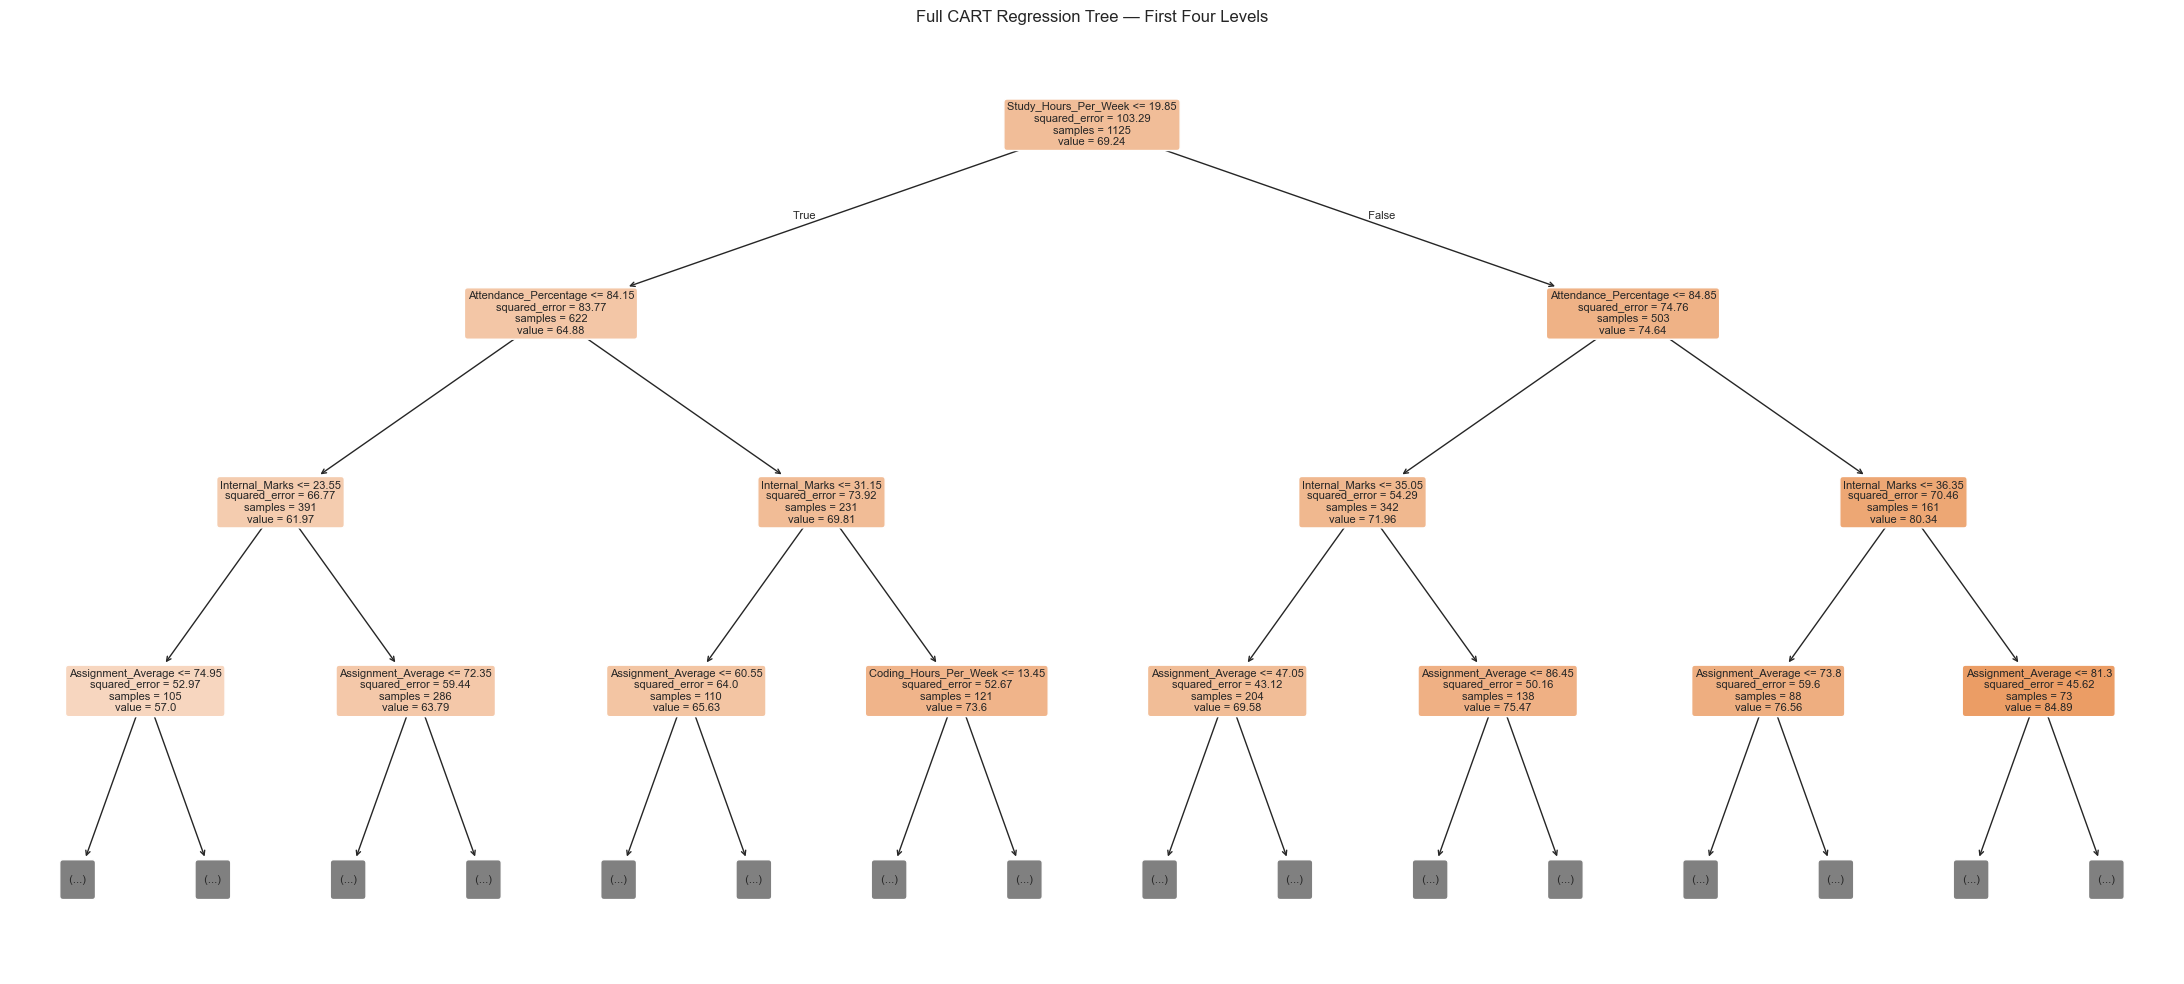

In [26]:
# Step 11: Visualize the first levels of the full tree

plt.figure(figsize=(22, 10))

plot_tree(
    full_tree,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    max_depth=3,
    precision=2,
    fontsize=8
)

plt.title("Full CART Regression Tree — First Four Levels")
plt.tight_layout()
plt.show()

## 12. Pre-pruning using GridSearchCV

Pre-pruning restricts tree growth while the tree is being built. We tune `max_depth` and `min_samples_leaf` using five-fold cross-validation on the training data only.

The scoring metric is negative root mean squared error (`neg_root_mean_squared_error`). GridSearchCV maximizes scores, so the negative form is used by scikit-learn; lower actual RMSE is better.

In [12]:
# Step 12: Pre-pruning with cross-validation

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

pre_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={
        "max_depth": [2, 3, 4, 5, 6, 8],
        "min_samples_leaf": [3, 5, 10, 20]
    },
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

pre_search.fit(X_train, y_train)

pre_pruned_tree = pre_search.best_estimator_

print("Best pre-pruning parameters:", pre_search.best_params_)
print("Best cross-validation RMSE:", round(-pre_search.best_score_, 3))
print("Tree depth:", pre_pruned_tree.get_depth())
print("Number of leaves:", pre_pruned_tree.get_n_leaves())

Best pre-pruning parameters: {'max_depth': 8, 'min_samples_leaf': 20}
Best cross-validation RMSE: 7.035
Tree depth: 8
Number of leaves: 43


## 13. Visualize the pre-pruned tree

The pre-pruned tree is usually smaller than the unrestricted tree. Compare its depth and number of leaves with the full tree.

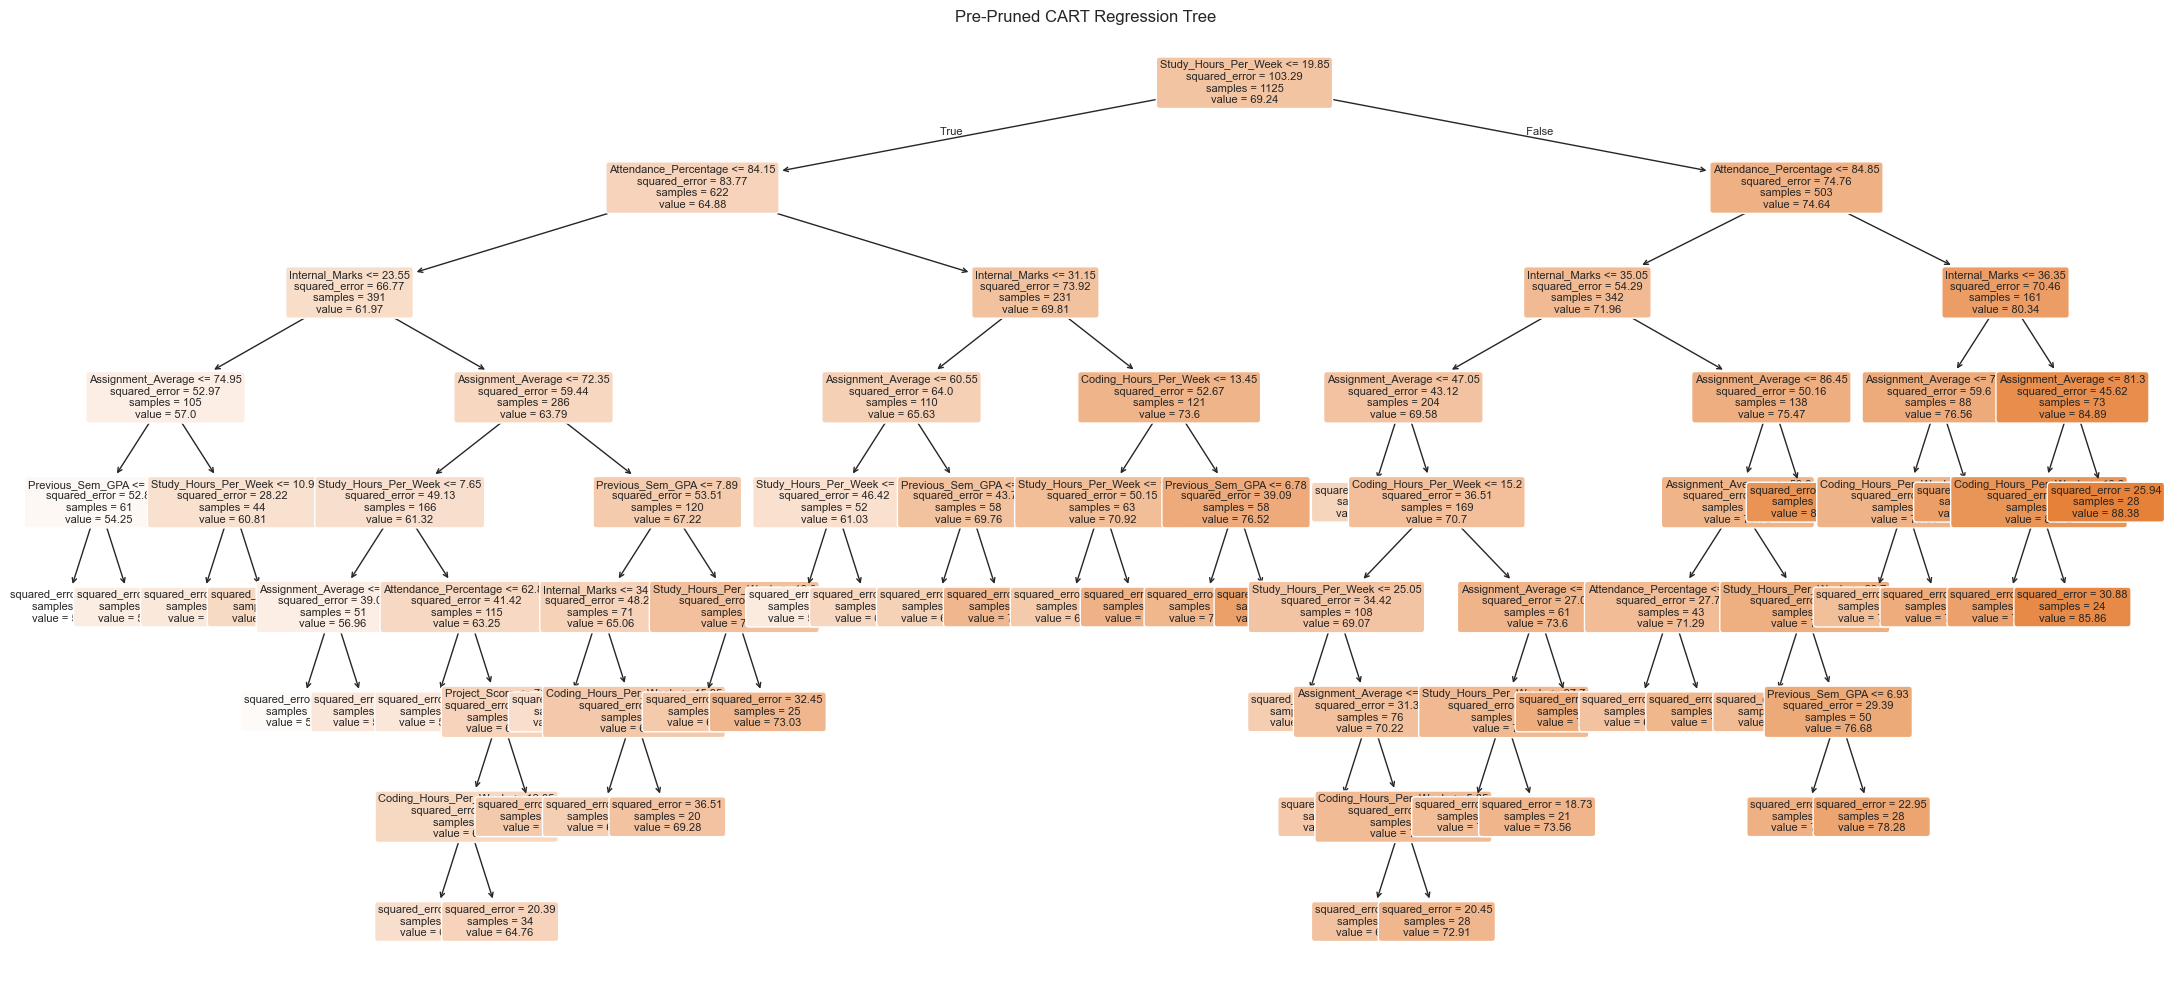

In [13]:
# Step 13: Plot the pre-pruned tree

plt.figure(figsize=(22, 10))

plot_tree(
    pre_pruned_tree,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    precision=2,
    fontsize=8
)

plt.title("Pre-Pruned CART Regression Tree")
plt.tight_layout()
plt.show()

## 14. Post-pruning using Cost Complexity Pruning

Post-pruning first grows a tree and then penalizes tree complexity. In scikit-learn, `ccp_alpha` controls the complexity penalty. Larger values generally produce smaller trees.

We evaluate candidate alpha values using cross-validation on training data. The held-out test set remains untouched until final evaluation.

In [14]:
# Step 14: Cost-complexity pruning path and alpha selection

pruning_path = full_tree.cost_complexity_pruning_path(X_train, y_train)

print("First 10 ccp_alpha values:")
print(np.round(pruning_path.ccp_alphas[:10], 5))

# Build a manageable grid spanning the pruning path.
alpha_grid = np.unique(
    np.quantile(
        pruning_path.ccp_alphas,
        np.linspace(0, 1, 50)
    )
)

post_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid={"ccp_alpha": alpha_grid},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

post_search.fit(X_train, y_train)

post_pruned_tree = post_search.best_estimator_

print("\nSelected ccp_alpha:", post_search.best_params_["ccp_alpha"])
print("Best cross-validation RMSE:", round(-post_search.best_score_, 3))
print("Tree depth:", post_pruned_tree.get_depth())
print("Number of leaves:", post_pruned_tree.get_n_leaves())

First 10 ccp_alpha values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Selected ccp_alpha: 0.5014800007482162
Best cross-validation RMSE: 7.349
Tree depth: 6
Number of leaves: 24


## 15. Visualize the post-pruned tree and pruning behaviour

The first plot shows how training impurity changes along the cost-complexity pruning path. The second shows the selected post-pruned tree.

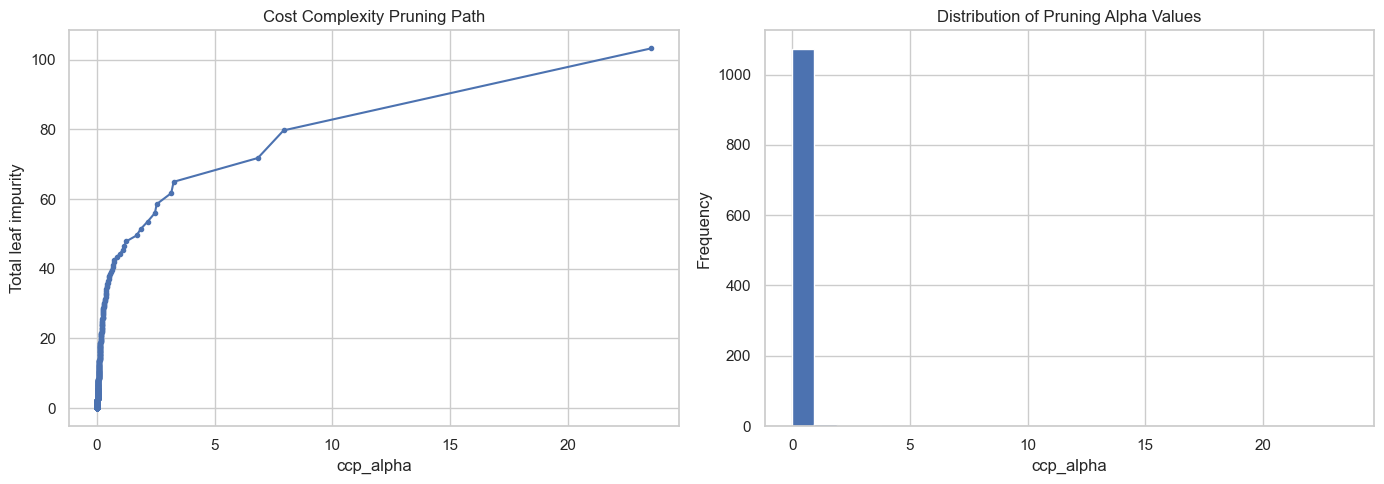

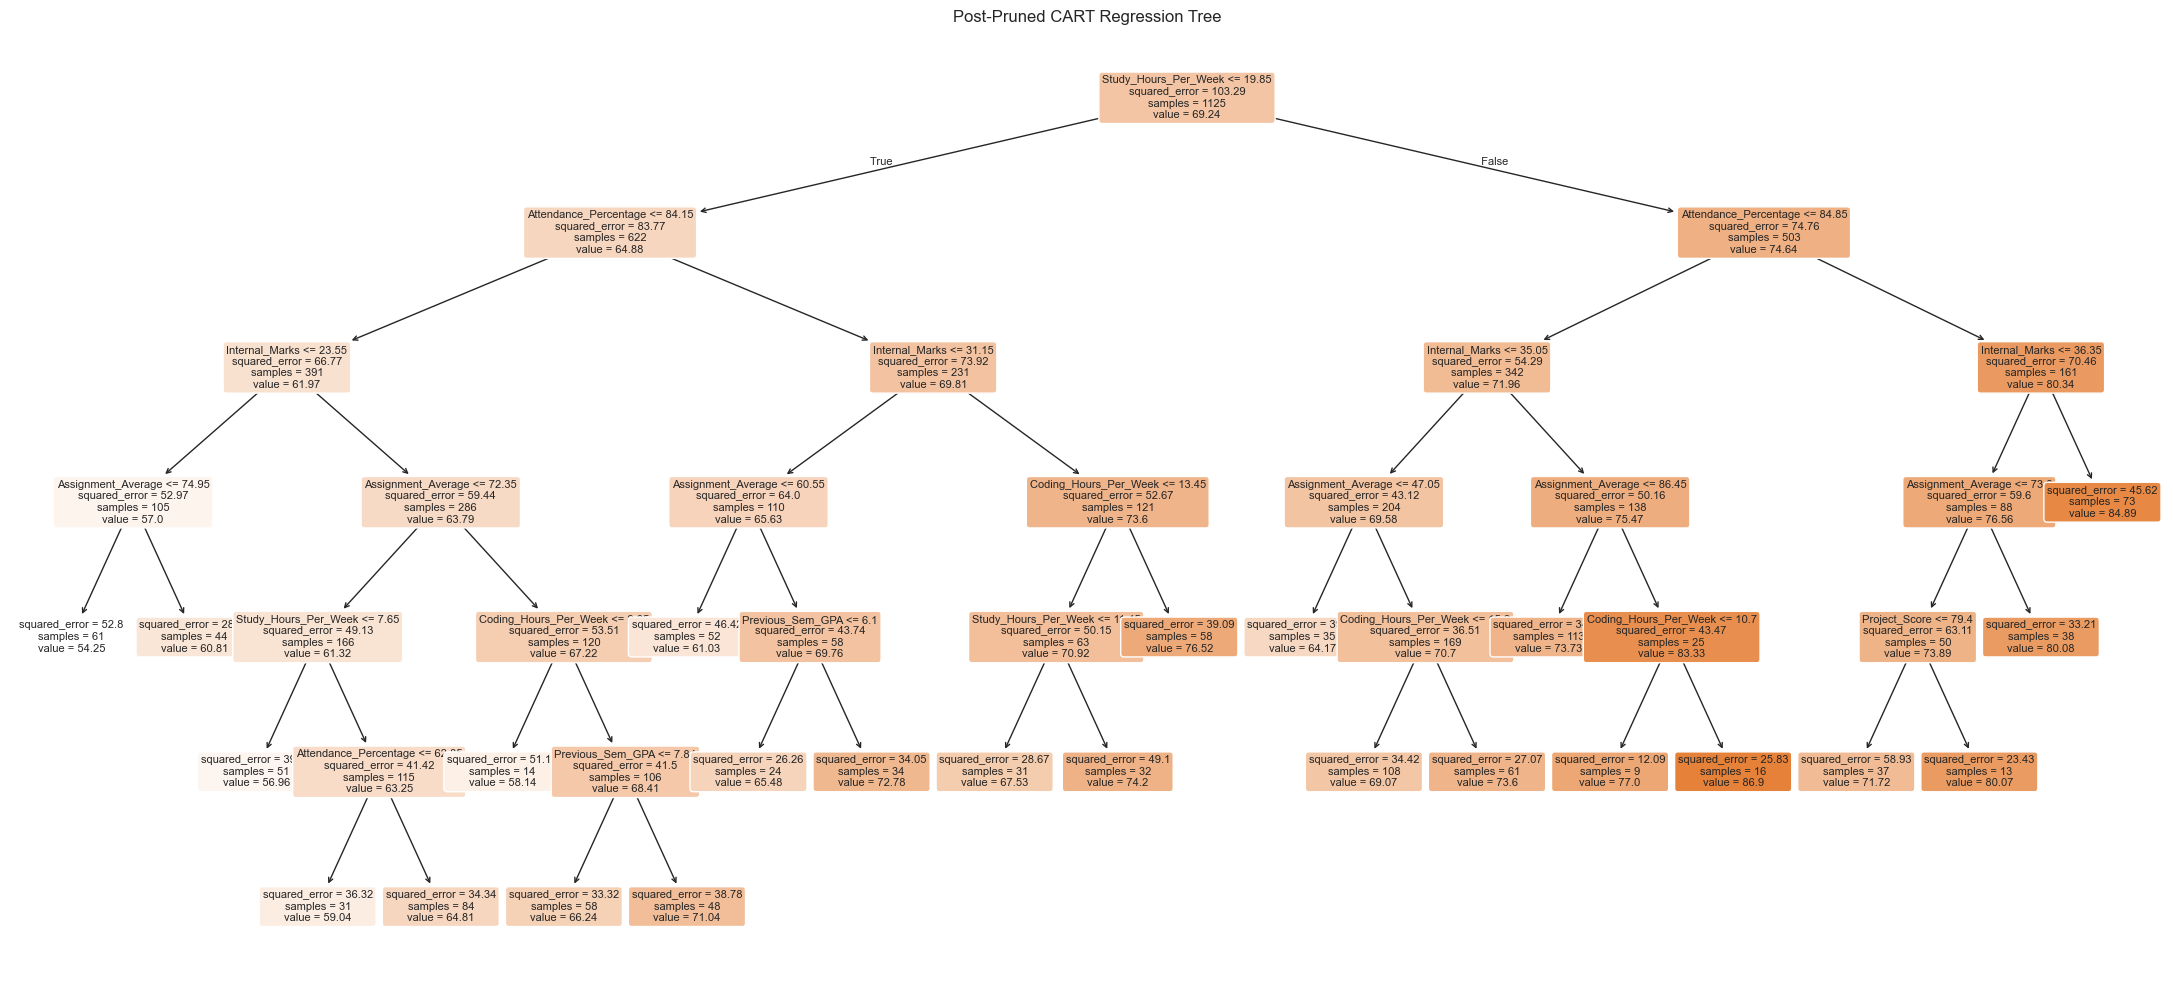

In [15]:
# Step 15: Plot pruning path and post-pruned tree

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    pruning_path.ccp_alphas,
    pruning_path.impurities,
    marker="."
)
axes[0].set_xlabel("ccp_alpha")
axes[0].set_ylabel("Total leaf impurity")
axes[0].set_title("Cost Complexity Pruning Path")

axes[1].hist(
    pruning_path.ccp_alphas,
    bins=25
)
axes[1].set_xlabel("ccp_alpha")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Distribution of Pruning Alpha Values")

plt.tight_layout()
plt.show()

plt.figure(figsize=(22, 10))

plot_tree(
    post_pruned_tree,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    precision=2,
    fontsize=8
)

plt.title("Post-Pruned CART Regression Tree")
plt.tight_layout()
plt.show()

## 16. Evaluate models against a baseline

A mean baseline predicts the average training target for every test record. A useful regression tree should improve on this simple reference.

Metrics:
- **MAE:** Average absolute prediction error; lower is better.
- **RMSE:** Square root of average squared error; lower is better and large errors are penalized more.
- **R²:** Proportion of target variation explained relative to a mean baseline; higher is better. It can be negative on test data.

All error values are measured in final-score points.

In [16]:
# Step 16: Compare baseline, full tree and pruned trees

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

models = {
    "Mean Baseline": baseline,
    "Full CART Tree": full_tree,
    "Pre-Pruned CART": pre_pruned_tree,
    "Post-Pruned CART": post_pruned_tree
}

comparison_rows = []

for name, model in models.items():
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    comparison_rows.append({
        "Model": name,
        "Depth": model.get_depth() if hasattr(model, "get_depth") else np.nan,
        "Leaves": model.get_n_leaves() if hasattr(model, "get_n_leaves") else np.nan,
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_predictions)),
        "Test MAE": mean_absolute_error(y_test, test_predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
        "Test R2": r2_score(y_test, test_predictions)
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison_df.round(3))

,Depth,Leaves,Train RMSE,Test MAE,Test RMSE,Test R2
Model,,,,,,
Mean Baseline,NaN,NaN,10.163,8.356,10.413,-0.013
Full CART Tree,18.0,1124.0,0.000,6.098,7.698,0.446
Pre-Pruned CART,8.0,43.0,5.778,5.040,6.369,0.621
Post-Pruned CART,6.0,24.0,6.125,5.392,6.713,0.579


## 17. Select the pruned model using cross-validation

We choose between the pre-pruned and post-pruned trees using their training-only cross-validation scores. The held-out test set is not used to choose the model.

After selection, we evaluate that model on the test set and inspect sample predictions and residuals.

In [17]:
# Step 17: Select the best pruned model using cross-validation

searches = {
    "Pre-Pruned CART": pre_search,
    "Post-Pruned CART": post_search
}

best_model_name = max(
    searches,
    key=lambda name: searches[name].best_score_
)

best_model = searches[best_model_name].best_estimator_

print("Selected model:", best_model_name)
print("Cross-validation RMSE:", round(-searches[best_model_name].best_score_, 3))
print("Final test RMSE:", round(
    np.sqrt(mean_squared_error(y_test, best_model.predict(X_test))), 3
))
print("Final test MAE:", round(
    mean_absolute_error(y_test, best_model.predict(X_test)), 3
))
print("Final test R2:", round(r2_score(y_test, best_model.predict(X_test)), 3))

Selected model: Pre-Pruned CART
Cross-validation RMSE: 7.035
Final test RMSE: 6.369
Final test MAE: 5.04
Final test R2: 0.621


## 18. Inspect actual values, predictions and residuals

A residual is the difference between the actual score and predicted score:

\[
Residual = Actual - Predicted
\]

Positive residual: the model underpredicted the score.  
Negative residual: the model overpredicted the score.

,Attendance_Percentage,Study_Hours_Per_Week,Assignment_Average,Internal_Marks,Previous_Sem_GPA,Sleep_Hours,Coding_Hours_Per_Week,Project_Score,Actual_Score,Predicted_Score,Residual
1116,61.2,7.7,73.3,30.4,6.60,7.1,23.6,53.6,61.87,61.76,0.11
1368,63.5,32.6,44.5,19.5,9.53,6.2,12.5,42.0,70.19,64.17,6.02
422,55.2,17.2,77.8,24.7,8.18,8.5,14.2,80.2,65.40,73.03,-7.63
413,95.4,19.7,38.5,47.9,9.71,8.8,24.0,75.7,83.54,79.42,4.12
451,94.8,1.4,71.4,41.0,6.07,7.4,6.3,95.7,74.03,67.53,6.50
861,87.9,2.8,36.8,17.7,9.48,9.0,12.5,62.2,56.81,58.13,-1.32
1063,83.1,18.6,73.1,21.1,4.84,5.4,1.8,43.3,68.93,52.18,16.75
741,60.0,3.1,47.3,25.3,6.49,9.3,9.6,35.5,45.42,53.65,-8.23
1272,72.9,31.2,87.4,23.5,4.62,7.7,15.1,53.9,79.56,72.91,6.65
259,81.7,32.3,37.8,47.6,5.85,7.1,10.7,93.0,68.31,73.24,-4.93


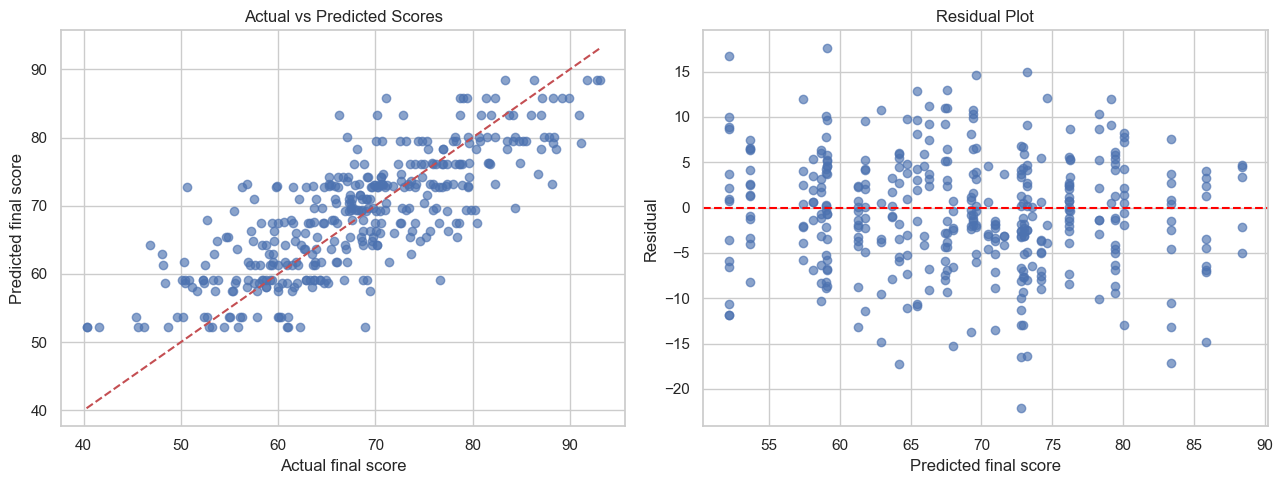

In [18]:
# Step 18: Prediction table and residual analysis

best_predictions = best_model.predict(X_test)

prediction_results = X_test.copy()
prediction_results["Actual_Score"] = y_test
prediction_results["Predicted_Score"] = best_predictions
prediction_results["Residual"] = (
    prediction_results["Actual_Score"]
    - prediction_results["Predicted_Score"]
)

display(prediction_results.head(15).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, best_predictions, alpha=0.65)
line_min = min(y_test.min(), best_predictions.min())
line_max = max(y_test.max(), best_predictions.max())
axes[0].plot([line_min, line_max], [line_min, line_max], "r--")
axes[0].set_xlabel("Actual final score")
axes[0].set_ylabel("Predicted final score")
axes[0].set_title("Actual vs Predicted Scores")

residuals = y_test - best_predictions
axes[1].scatter(best_predictions, residuals, alpha=0.65)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted final score")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

## 19. Feature importance

A fitted CART tree provides impurity-based feature importance. Larger values indicate that a feature contributed more to reducing squared error across the tree.

This importance is model-specific and does not prove that a feature causes higher or lower academic performance. Correlated features can share or distort importance.

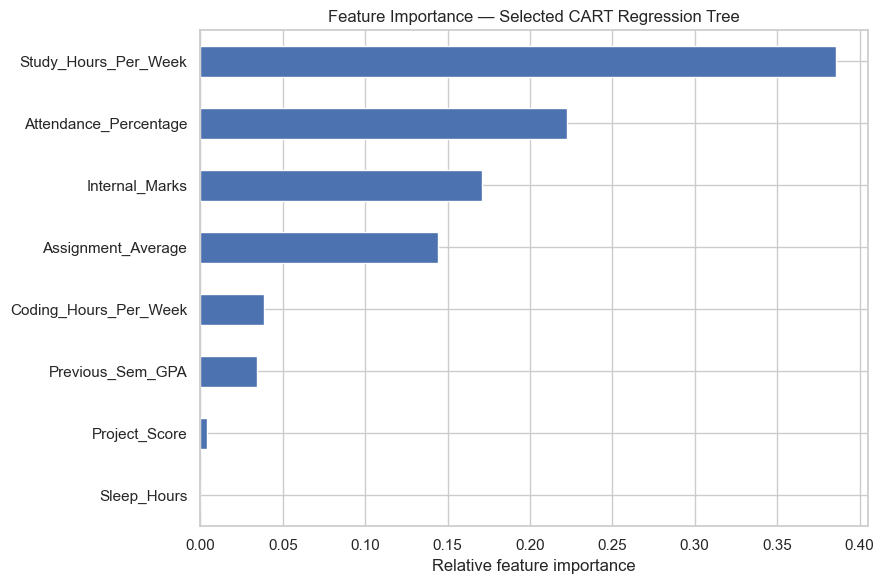

,Importance
Study_Hours_Per_Week,0.3858
Attendance_Percentage,0.2228
Internal_Marks,0.1707
Assignment_Average,0.1440
Coding_Hours_Per_Week,0.0387
Previous_Sem_GPA,0.0342
Project_Score,0.0038
Sleep_Hours,0.0000


In [19]:
# Step 19: Feature importance of the selected tree

importance = pd.Series(
    best_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 6))
importance.plot(kind="barh")
plt.xlabel("Relative feature importance")
plt.title("Feature Importance — Selected CART Regression Tree")
plt.tight_layout()
plt.show()

display(importance.sort_values(ascending=False).to_frame("Importance").round(4))

## 20. Predict the score for a hypothetical B.Tech student

We create one hypothetical student with the same feature columns used during training. The selected regression tree predicts a final semester score on the 0–100 scale.

This is a demonstration of model inference, not a real academic prediction.

In [20]:
# Step 20: Predict for a new hypothetical student

new_student = pd.DataFrame({
    "Attendance_Percentage": [88.0],
    "Study_Hours_Per_Week": [18.0],
    "Assignment_Average": [82.0],
    "Internal_Marks": [41.0],
    "Previous_Sem_GPA": [8.2],
    "Sleep_Hours": [7.0],
    "Coding_Hours_Per_Week": [10.0],
    "Project_Score": [86.0]
})

print("Hypothetical student details:")
display(new_student)

predicted_score = best_model.predict(new_student)[0]

print(f"Predicted Final Semester Score: {predicted_score:.2f} / 100")

Hypothetical student details:


,Attendance_Percentage,Study_Hours_Per_Week,Assignment_Average,Internal_Marks,Previous_Sem_GPA,Sleep_Hours,Coding_Hours_Per_Week,Project_Score
0,88.0,18.0,82.0,41.0,8.2,7.0,10.0,86.0


Predicted Final Semester Score: 74.20 / 100


## 21. Display the selected CART regression rules

The textual rules make the tree's decisions easier to inspect. Each terminal leaf predicts the mean training score for the observations that reach that leaf.

In [21]:
# Step 21: Display decision rules

print("Selected model:", best_model_name)
print("\nCART Regression Tree Rules:")
print(
    export_text(
        best_model,
        feature_names=X.columns.tolist(),
        decimals=2
    )
)

Selected model: Pre-Pruned CART

CART Regression Tree Rules:
|--- Study_Hours_Per_Week <= 19.85
|   |--- Attendance_Percentage <= 84.15
|   |   |--- Internal_Marks <= 23.55
|   |   |   |--- Assignment_Average <= 74.95
|   |   |   |   |--- Previous_Sem_GPA <= 7.81
|   |   |   |   |   |--- value: [52.18]
|   |   |   |   |--- Previous_Sem_GPA >  7.81
|   |   |   |   |   |--- value: [57.44]
|   |   |   |--- Assignment_Average >  74.95
|   |   |   |   |--- Study_Hours_Per_Week <= 10.90
|   |   |   |   |   |--- value: [58.70]
|   |   |   |   |--- Study_Hours_Per_Week >  10.90
|   |   |   |   |   |--- value: [62.91]
|   |   |--- Internal_Marks >  23.55
|   |   |   |--- Assignment_Average <= 72.35
|   |   |   |   |--- Study_Hours_Per_Week <= 7.65
|   |   |   |   |   |--- Assignment_Average <= 50.00
|   |   |   |   |   |   |--- value: [53.65]
|   |   |   |   |   |--- Assignment_Average >  50.00
|   |   |   |   |   |   |--- value: [59.09]
|   |   |   |   |--- Study_Hours_Per_Week >  7.65
|   |  

# 22. Observations and conclusion

Complete this section after running all cells and reviewing the actual output.

## Observations to discuss

1. **Regression CART criterion:** The manual split calculation uses parent MSE, weighted child MSE and MSE reduction. The split with the smallest weighted MSE is preferred.
2. **Full tree:** Compare its training and test RMSE. A much smaller training error than test error can indicate overfitting.
3. **Pre-pruning:** Restricting maximum depth and minimum leaf size can reduce tree complexity.
4. **Post-pruning:** Cost-complexity pruning uses `ccp_alpha` to penalize unnecessary leaves.
5. **Model selection:** Cross-validation on training data selects pruning settings; the held-out test set estimates final generalization.
6. **Baseline comparison:** Compare each tree with the mean predictor to check whether the model learns useful patterns.
7. **Feature importance:** Discuss the features ranked highly by the selected tree, while remembering that importance is not causation.

## Limitations

- The dataset is synthetic and its target is generated from assumed relationships.
- A single train-test split can vary with the random seed.

## Final conclusion

CART regression was implemented using a B.Tech student academic-performance dataset. The notebook demonstrated manual squared-error split selection, full-tree construction, pre-pruning, post-pruning, cross-validation, regression evaluation and prediction for a hypothetical student. 